In [1]:
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
# Vamos criar nossos dados sintéticos como passado em sala
N = 12
M = 9
dist = 1
diag = dist * np.sqrt(2)

true_p = np.ones(9)
true_p[4] = 40

print(true_p)

[ 1.  1.  1.  1. 40.  1.  1.  1.  1.]


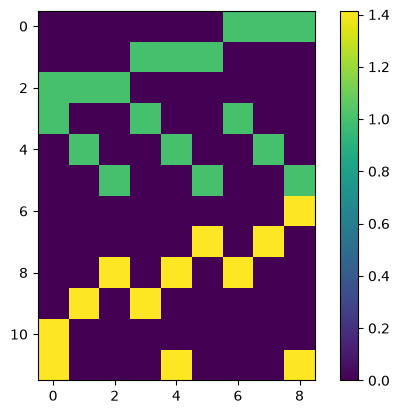

In [3]:
# Vamos construir nossa matriz jacobiana 
G = np.zeros((N,M))
# Equações Horizontais
G[0, [6, 7, 8]] = dist      # eq_1: p7 + p8 + p9
G[1, [3, 4, 5]] = dist      # eq_2: p4 + p5 + p6
G[2, [0, 1, 2]] = dist      # eq_3: p1 + p2 + p3
# Equações Verticais
G[3, [0, 3, 6]] = dist      # eq_4: p1 + p4 + p7
G[4, [1, 4, 7]] = dist      # eq_5: p2 + p5 + p8
G[5, [2, 5, 8]] = dist      # eq_6: p3 + p6 + p9
# Equações Diagonais
G[6, [-1]]       = diag      # eq_7: p9
G[7, [5, 7]]    = diag      # eq_8: p6 + p8
G[8, [2, 4, 6]] = diag      # eq_9: p3 + p5 + p7
G[9, [1, 3]]    = diag      # eq_10: p2 + p4
G[10, [0]]      = diag      # eq_11: p1
G[11, [0, 4, 8]]= diag      # eq_12: p1 + p5 + p9
#G[12, [6]] = diag
#G[13, [3,7]] = diag
#G[14, [1,5]] = diag
#G[15,[2]] = diag
plt.imshow(G)
plt.colorbar()

In [4]:
# Vetor de observações 
#y = np.array([eq_1, eq_2, eq_3, eq_4, eq_5, eq_6,eq_7, eq_8, eq_9, eq_10, eq_11, eq_12])
data = G @ true_p
data += np.random.default_rng().normal(0, 0.01 * np.abs(data).max(), data.shape)
# Estimativa por mínimos quadrados
p_est = np.linalg.solve(G.T @ G, G.T @ data)
# Reconverte o vetor estimado para a grade 3x3 original
p_grid = p_est.reshape((3, 3))
# Printa o resultado
p_grid

array([[ 1.09279927, -6.45890403,  8.80558974],
       [ 8.12993787, 39.7663776 , -6.069576  ],
       [-6.7395654 ,  8.52346902,  0.8591859 ]])

# Análise de SVD e solução por pseudo-inversão

In [5]:
U, S, Vt = np.linalg.svd(G)
# Se os valores singulares de S forem igual a 0 ou muito proximo de 0 entramos 
# em um espaço nulo 
S

array([3.62258273e+00, 2.44948974e+00, 2.44948974e+00, 2.20836917e+00,
       1.73205081e+00, 1.73205081e+00, 1.73205081e+00, 1.73205081e+00,
       1.92239241e-16])

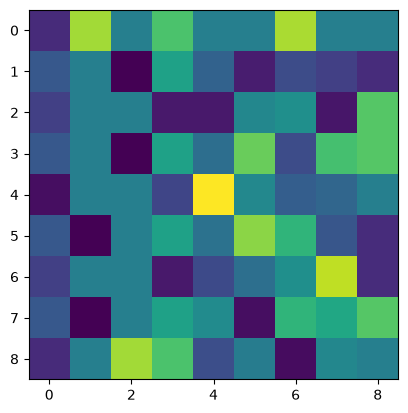

In [6]:
plt.imshow(Vt.T)

In [7]:
data = G @ true_p
data += np.random.default_rng().normal(0, 0.01 * np.abs(data).max(), data.shape)
#Solução por SVD
U, S, Vt = np.linalg.svd(G)
k = S.size - 1 
Sp = np.diag(S[:k])
Up = U[:, :k]
Vp = Vt.T[:, :k]
# Estimativa de minimos quadrados com a pseudo inversa de Moore Penrose
p_pseudo = Vp @ np.linalg.inv(Sp) @ Up.T @ data
p_pseudo.reshape((3,3))

array([[ 0.57179096,  1.02647245,  0.78731997],
       [ 0.64001047, 39.96390498,  1.24126474],
       [ 0.59281837,  1.43322513,  1.36499113]])

## Adicionando vinculos ao problema 

$p_3 = 1$ e $p_7 = 1$

In [8]:
c = np.zeros(true_p.size)
c [2] = 1
c[6] = 1
A =np.zeros((2, true_p.size))
A[0,2] = 1
A[1,6] = 1
A

array([[0., 0., 1., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0.]])

In [9]:
B = np.linalg.inv(G.T @ G)
p = B @ ((G.T @ data - A.T @ np.linalg.inv(A @ B @ A.T) @ A @ (B @ G.T @ data - c)))
p.reshape((3,3))

array([[ 0.28071308, 12.57511478,  4.15844031],
       [-1.35142195, 38.10164967,  5.6408944 ],
       [ 6.14747704, -1.59814233,  0.96320817]])

Isso no fim das contas não resolve nossos problemas de instabilibade 

Mas podemos combinar isso com a solução SVD

In [10]:
data = G @ true_p
data += np.random.default_rng().normal(0, 0.01 * np.abs(data).max(), data.shape)
# Vamos usar o SVD para calcular a inversa de G.TG
U, S, Vt = np.linalg.svd(G)
k = S.size - 1 
Sp_inv= np.diag(1 / S[:k])
Up = U[:, :k]
Vp = Vt.T[:, :k]
B = Vp @ Sp_inv ** 2 @ Vp.T
p = B @ ((G.T @ data - A.T @ np.linalg.inv(A @ B @ A.T) @ A @ (B @ G.T @ data - c)))
p.reshape((3,3))

array([[ 0.65687069,  0.98496643,  1.        ],
       [ 1.1692235 , 40.09180247,  1.11000829],
       [ 1.        ,  0.92575122,  0.91275095]])

## Solução com regularização

In [15]:
lamb = 1e0
data += np.random.default_rng().normal(0, 0.01 * np.abs(data).max(), data.shape)
p_regul = np.linalg.solve(G.T @ G + lamb * np.identity(G.shape[1]), G.T @ data)
p_regul.reshape((3,3))

array([[ 2.03254177,  1.29358581,  2.32128887],
       [ 1.18685362, 32.21267364,  1.27549351],
       [ 2.57793139,  1.63886822,  1.94859387]])

In [16]:
data

array([ 2.90209518, 40.92471371,  2.33849544,  2.56505309, 41.57820009,
        2.10208274,  1.4820736 ,  3.03901594, 58.90007948,  2.21346573,
        1.54320057, 58.57957076])

In [17]:
G @ p_regul

array([ 6.16539349, 34.67502078,  5.64741645,  5.79732679, 35.14512766,
        5.54537626,  2.75572789,  4.12152988, 52.48414369,  3.50787108,
        2.87444814, 51.18577597])

Se o modelo não se ajusta os dados quer dizer que o modelo não reflete a realidade

Como por exemplo, um fator de regularização muito grande $\lambda = 10³$

Mas se o modelo ajusta os dados também não quer dizer que o modelo está correto, porque o modelo é uma simpligicação do que de fato acontece na natureza

[4.44368580e-01 4.09491506e-15 1.67683294e-14 6.86648845e-14
 2.81176870e-13 1.15139540e-12 4.71486636e-12 1.93069773e-11
 7.90604321e-11 3.23745754e-10 1.32571137e-09 5.42867544e-09
 2.22299648e-08 9.10298178e-08 3.72759372e-07 1.52641797e-06
 6.25055193e-06 2.55954792e-05 1.04811313e-04 4.29193426e-04
 1.75751062e-03 7.19685673e-03 2.94705170e-02 1.20679264e-01
 4.94171336e-01 2.02358965e+00 8.28642773e+00 3.39322177e+01
 1.38949549e+02 5.68986603e+02 2.32995181e+03 9.54095476e+03
 3.90693994e+04 1.59985872e+05 6.55128557e+05 2.68269580e+06
 1.09854114e+07 4.49843267e+07 1.84206997e+08 7.54312006e+08
 3.08884360e+09 1.26485522e+10 5.17947468e+10 2.12095089e+11
 8.68511374e+11 3.55648031e+12 1.45634848e+13 5.96362332e+13
 2.44205309e+14 1.00000000e+15] [1.66166362e+03 6.06473051e-01 6.06473051e-01 6.06473051e-01
 6.06473051e-01 6.06473051e-01 6.06473051e-01 6.06473051e-01
 6.06473051e-01 6.06473051e-01 6.06473051e-01 6.06473051e-01
 6.06473051e-01 6.06473051e-01 6.06473051e-01 6.06473

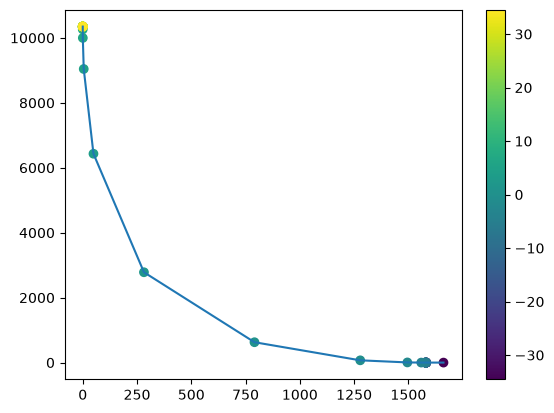

In [18]:
lambdas = np.logspace(-15, 15, 50)
misfit = np.empty(lambdas.size)
normp = np.empty(lambdas.size)
for i, lamb in enumerate(lambdas):
    p_regul = np.linalg.solve(G.T @ G + lamb * np.identity(G.shape[1]), G.T @ data)
    residuals = data - G @ p_regul
    misfit[i] = np.linalg.norm(residuals) ** 2
    normp[i] = np.linalg.norm(p_regul) ** 2
    print(misfit, normp)
    
plt.plot(normp, misfit, "-")
plt.scatter(normp, misfit, c=np.log(lambdas))
plt.colorbar()
